# Building a neuron with several synaptic memories

We'll create a stateful layer whose hidden states include a matrix: each input feature will have four filtered histories with different decays, and learned weights will combine those histories back into a per-neuron scalar before the membrane integrates them.

This gives us a reason to use more than a vector state while working through the tools available to a custom layer. We'll connect the equations to state declarations and transformed parameters, inspect what the histories contain, train the layer in a model, and save and restore its matrix states.

This is an extensibility lesson, not a proposal for a benchmark-winning neuron. We'll use a short training run to connect the new state update to an observed learning result.

After installing the repository, use `pip install -r examples/custom_neuron/requirements.txt` and open `examples/custom_neuron/tutorial.ipynb`. The complete automatic program is the neighboring `main.py`. We'll reuse the patch-MNIST task so the focus stays on the new layer rather than another dataset.

Source on GitHub: [notebook](https://github.com/Yegor-men/tracetorch/blob/main/examples/custom_neuron/tutorial.ipynb) and [complete program](https://github.com/Yegor-men/tracetorch/blob/main/examples/custom_neuron/main.py).

In [1]:
from pathlib import Path
from time import perf_counter
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
import tracetorch as tt

# Keep saved figures readable regardless of the notebook editor's theme.
plt.style.use("default")
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cpu"
DATA_ROOT = Path("../data")
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)


## 1. Giving the matrix state a purpose

A single running average follows input at one timescale. If we give each feature several averages, we can keep both recent and older input, then let the neuron learn which combination helps the task. Let $F$ be the feature count and $K$ the number of histories per feature. For batch size $B$, our quantities have these shapes:

| Quantity | Shape | Role |
|---|---|---|
| Input | `[B, F]` | Current input values |
| Synaptic histories | `[B, F, K]` | Several memories for each feature |
| Membrane and previous firing | `[B, F]` | Membrane integration and delayed reset |
| Decays and mixture weights | `[F, K]` | Learned parameters shared across the batch |

We'll update history $k$ of feature $f$ as an exponential moving average:

$$a_{t,f,k}=\alpha_{f,k}a_{t-1,f,k}+(1-\alpha_{f,k})x_{t,f}.$$

A larger decay $\alpha_{f,k}$ gives a slower response with longer memory. To combine the histories, we'll turn learned logits $q$ into normalized weights along the history axis:

$$w_{f,k}=\frac{e^{q_{f,k}}}{\sum_j e^{q_{f,j}}}, \qquad c_{t,f}=\sum_k w_{f,k}a_{t,f,k}.$$

Each row of weights is nonnegative and sums to one, so $c$ is a weighted average of that feature's histories. It's also back to one scalar per feature, which lets us feed it into an ordinary LIB-style membrane:

$$m_t=\beta(m_{t-1}-\theta s_{t-1})+c_t, \qquad s_t=\sigma(4(m_t-\theta)).$$

We'll use smooth firing intensities and the same delayed reset before membrane decay. The part we're changing is therefore the input filtering: several synaptic memories feed a familiar membrane update.

## 2. Declaring states and tensor parameters

We'll inherit from `tt.Layer()` because our decays and mixture weights have shape `[F, K]`. The generic base supports arbitrary parameter shapes, whereas the SNN convenience base is designed around scalar and one-dimensional per-neuron initialization.

Each `define_state` call records the trailing shape of a state. On the first input, `zero_states(x)` combines that shape with the input's leading dimensions and allocates zeros; until then, the state is `None`. That lets the same layer handle a batch size chosen by the caller rather than fixed in its constructor.

In [2]:
def normalize_mixture(logits):
    return torch.softmax(logits, dim=-1)


class MultiTraceLIB(tt.Layer):
    """Filter each feature at several timescales, then integrate and fire.

    Input and output: [..., num_features]. Synaptic state: [..., num_features, K].
    Reset uses the previous smooth firing output before membrane decay.
    """

    def __init__(self, num_features, trace_decays=(0.2, 0.5, 0.8, 0.95)):
        super().__init__()
        self.num_features = num_features
        self.num_traces = len(trace_decays)
        self.define_state("syn", (num_features, self.num_traces))
        self.define_state("mem", (num_features,))
        self.define_state("prev_output", (num_features,))
        decays = torch.tensor(trace_decays).expand(num_features, -1).clone()
        self.define_parameter("alpha", decays, initialization_fn=tt.inverse_fn.sigmoid,
                              activation_fn=torch.sigmoid)
        self.define_parameter("mixture", torch.full_like(decays, 1 / self.num_traces),
                              initialization_fn=torch.log, activation_fn=normalize_mixture)
        self.define_parameter("beta", torch.full((num_features,), 0.9),
                              initialization_fn=tt.inverse_fn.sigmoid, activation_fn=torch.sigmoid)
        self.define_parameter("threshold", torch.ones(num_features),
                              initialization_fn=tt.inverse_fn.softplus, activation_fn=F.softplus)

    def forward(self, x):
        self.zero_states(x)
        self.syn = self.alpha * self.syn + (1 - self.alpha) * x.unsqueeze(-1)
        current = (self.mixture * self.syn).sum(dim=-1)
        self.mem = self.beta * (self.mem - self.threshold * self.prev_output) + current
        self.prev_output = tt.snn.spike_fn.smooth(self.mem - self.threshold)
        return self.prev_output

The initialization functions let us specify effective values, such as decay 0.9, while storing unconstrained raw parameters for the optimizer. Inverse sigmoid maps that initial decay into its raw value; sigmoid brings it back into `(0, 1)` whenever we access it. Thresholds use softplus to remain positive.

For the mixture, we initialize with equal positive probabilities and take their logarithms. Applying softmax to those logits recovers the initial probabilities, then keeps the learned rows normalized as training changes the logits.

Names such as `self.alpha` apply these transformations when accessed, while `raw_alpha`, `raw_mixture`, `raw_beta` and `raw_threshold` are the registered PyTorch parameters. We can inspect the shapes and registered names before putting the layer in a network.

In [3]:
layer = MultiTraceLIB(3)
print("Before input:", layer.syn, layer.mem)
output = layer(torch.zeros(2, 3))
print("Synaptic state:", layer.syn.shape)
print("Membrane:", layer.mem.shape)
print("Output:", output.shape)
print("Mixture sums:", layer.mixture.sum(-1))
print("Registered weights:", list(layer.state_dict()))

Before input: None None
Synaptic state: torch.Size([2, 3, 4])
Membrane: torch.Size([2, 3])
Output: torch.Size([2, 3])
Mixture sums: tensor([1., 1., 1.], grad_fn=<SumBackward1>)
Registered weights: ['raw_alpha', 'raw_mixture', 'raw_beta', 'raw_threshold']


We now have a matrix state of shape `[2, 3, 4]` beside membrane and output vectors of shape `[2, 3]`. The parameters don't carry a batch axis because the learned dynamics are shared across samples; the memories themselves remain independent.

In `forward`, `x.unsqueeze(-1)` gives each feature a singleton history axis so it can broadcast across all four decays. The final sum removes only that history axis, returning a per-feature current for the membrane.

## 3. Watching the different memories

Let's send a short pulse into one feature and record the histories after each update. This lets us inspect what the matrix represents directly, before judging it through a trained prediction.

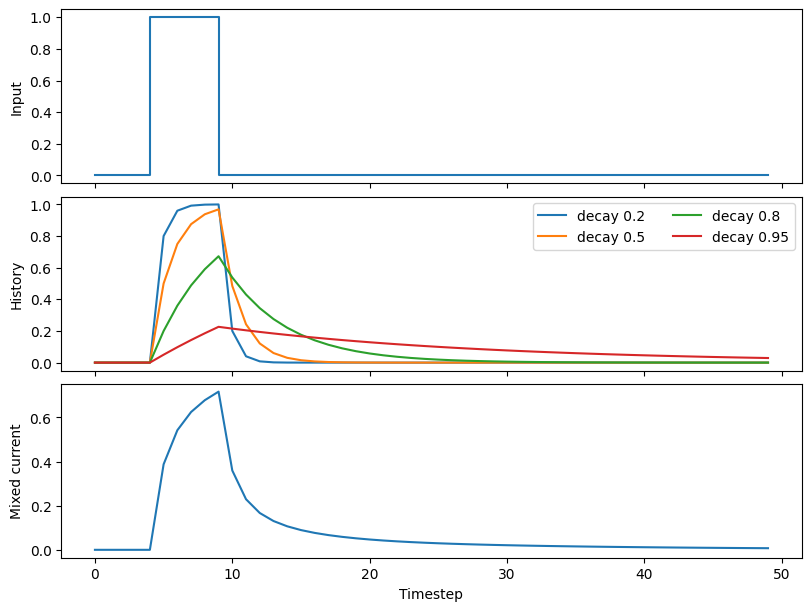

In [4]:
layer = MultiTraceLIB(1)
inputs = torch.cat([torch.zeros(5), torch.ones(5), torch.zeros(40)])
traces, currents = [], []
with torch.no_grad():
    for value in inputs:
        layer(value.reshape(1, 1))
        traces.append(layer.syn[0, 0].clone())
        currents.append((layer.mixture[0] * layer.syn[0, 0]).sum())
traces, currents = torch.stack(traces), torch.stack(currents)
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True, layout="constrained")
axes[0].step(range(len(inputs)), inputs)
axes[0].set_ylabel("Input")
for index, decay in enumerate((0.2, 0.5, 0.8, 0.95)):
    axes[1].plot(traces[:, index], label=f"decay {decay}")
axes[1].set_ylabel("History")
axes[1].legend(ncol=2)
axes[2].plot(currents)
axes[2].set_ylabel("Mixed current")
axes[2].set_xlabel("Timestep")
plt.show()

The short-memory histories rise quickly and fade quickly, while the longer ones respond slowly and remain after the pulse. At initialization, the mixture averages all four equally, so the bottom curve combines their different responses.

Try changing `trace_decays` when constructing a fresh layer while keeping the pulse fixed. Predicting how the rise and tail will change helps connect the extra state axis to actual temporal behavior, rather than just another tensor dimension.

## 4. Using other leading dimensions

So far we've used batch and feature axes, but the allocation rule can also preserve spatial positions. Each declared state replaces the final feature axis with its own trailing shape, leaving the other positions independent. Let's give the same layer a channel-last image-like input.

In [5]:
layer.reset_states()
layer(torch.zeros(2, 3, 5, 1))
print("Input [B, H, W, F] gives synaptic state:", layer.syn.shape)
print("Membrane:", layer.mem.shape)
layer.reset_states()

Input [B, H, W, F] gives synaptic state: torch.Size([2, 3, 5, 1, 4])
Membrane: torch.Size([2, 3, 5, 1])


The histories have shape `[2, 3, 5, 1, 4]`: each batch and spatial position now has its own feature-by-history matrix. We haven't put time into the tensor layout; we'll still advance it by calling the layer in an outer loop.

For other designs, `define_state` accepts a negative `dim` to replace more trailing input dimensions, or `dim=None` to append a state shape to the complete input shape. This neuron only needs the default `dim=-1`, but the allocation rule can follow what a different state represents.

## 5. Controlling learnability and gradient history

We can hold a transformed parameter fixed through the public setter, then compile and decompile without losing that choice. Let's fix `alpha`, leave the mixture trainable, and inspect what happens across compilation. We'll also compare detaching a state with resetting it.

In [6]:
layer.set_parameter_learnable("alpha", False)
layer.compile_parameters()
print("Compiled mixture trainable:", layer.raw_mixture.requires_grad)
layer.decompile_parameters()
print("Restored mixture trainable:", layer.raw_mixture.requires_grad)
print("Fixed decay still fixed:", not layer.raw_alpha.requires_grad)
layer.set_parameter_learnable("alpha", True)
layer.reset_states()
layer(torch.ones(1, 1, requires_grad=True))
print("State has gradient history:", layer.syn.grad_fn is not None)
layer.detach_states()
print("After detach, history remains connected:", layer.syn.grad_fn is not None)
print("Numerical history remains:", layer.syn)
layer.reset_states()
print("After reset:", layer.syn)

Compiled mixture trainable: False
Restored mixture trainable: True
Fixed decay still fixed: True
State has gradient history: True
After detach, history remains connected: False
Numerical history remains: tensor([[[0.8000, 0.5000, 0.2000, 0.0500]]])
After reset: None


The mixture becomes temporarily frozen while compiled and returns to being trainable afterward, while our deliberately fixed decay stays fixed. Detaching leaves the numerical histories available but cuts their gradient connection; resetting then discards the values and lets the next input allocate a new independent shape.

Our transformed decays and mixture weights depend only on learned parameters, so their effective values can be cached for inference. A gate predicted from each incoming input would still need to run on every call, and wouldn't belong in that parameter cache.

## 6. Composing a model and training it

We'll put linear projections before and after the custom neuron, then use the same fixed, shared-decay LI evidence collector as in the MNIST lesson. Its ten values already represent class scores, so there is no projection after it. The projections supply feature mixing, while our layer supplies the histories and their update. PyTorch registers the ordinary projection weights alongside our custom raw parameters, so one optimizer can train the whole model.

In [7]:
class CustomPatchSNN(tt.Model):
    def __init__(self, width=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(16, width), MultiTraceLIB(width),
            nn.Linear(width, 10), tt.snn.LI(10, beta=0.9, beta_rank=0, learn_beta=False),
        )

    def forward(self, patch):
        return self.net(patch)

We'll prepare the same 49 image patches as in the MNIST walkthrough: a 4 × 4 window with stride 4 turns each image into `[49, B, 16]`. The preparation code is included here so we can run this notebook on its own, while the shared `../data` path lets it reuse the MNIST download.

In [8]:
def images_to_patch_sequence(images):
    return F.unfold(images, kernel_size=4, stride=4).permute(2, 0, 1).contiguous()


def get_dataloaders(data_root, batch_size, train_samples, test_samples, seed):
    train = datasets.MNIST(data_root, train=True, download=True, transform=transforms.ToTensor())
    test = datasets.MNIST(data_root, train=False, download=True, transform=transforms.ToTensor())
    generator = torch.Generator().manual_seed(seed)
    if train_samples:
        train = Subset(train, torch.randperm(len(train), generator=generator)[:train_samples].tolist())
    if test_samples:
        test = Subset(test, torch.randperm(len(test), generator=generator)[:test_samples].tolist())
    return (DataLoader(train, batch_size=batch_size, shuffle=True, generator=generator),
            DataLoader(test, batch_size=batch_size))

The training procedure doesn't need to know that one state is now a matrix. We still reset before independent image batches, keep the states through the patches, and calculate loss from the final scores. Model-level state operations find all the declared states, so the timestep loop stays focused on the task.

In [9]:
def forward_sequence(model, sequence):
    model.reset_states()
    for patch in sequence:
        logits = model(patch)
    return logits


def run_epoch(model, dataloader, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = total_correct = total_count = 0
    with torch.set_grad_enabled(training):
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = forward_sequence(model, images_to_patch_sequence(images))
            loss = F.cross_entropy(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.numel()
            total_correct += (logits.argmax(-1) == labels).sum().item()
            total_count += labels.numel()
    model.reset_states()
    return total_loss / total_count, total_correct / total_count

In [10]:
torch.manual_seed(0)
train_loader, test_loader = get_dataloaders(DATA_ROOT, 64, 4096, 1024, seed=0)
model = CustomPatchSNN(width=64).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
loss, accuracy = run_epoch(model, test_loader, device)
history = {"train_loss": [], "test_loss": [loss], "test_accuracy": [accuracy]}
print(f"Before training: loss={loss:.3f}, accuracy={accuracy:.1%}")
started = perf_counter()
for epoch in range(1, 6):
    train_loss, _ = run_epoch(model, train_loader, device, optimizer)
    loss, accuracy = run_epoch(model, test_loader, device)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(loss)
    history["test_accuracy"].append(accuracy)
    print(f"Epoch {epoch}: loss={loss:.3f}, accuracy={accuracy:.1%}")
print(f"Training and evaluation: {perf_counter() - started:.1f}s")

Before training: loss=2.699, accuracy=8.8%
Epoch 1: loss=2.252, accuracy=20.1%
Epoch 2: loss=2.113, accuracy=27.1%
Epoch 3: loss=2.022, accuracy=28.5%
Epoch 4: loss=1.969, accuracy=30.3%
Epoch 5: loss=1.929, accuracy=31.2%
Training and evaluation: 3.9s


In [11]:
def plot_history(history):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
    axes[0].plot(epochs, history["train_loss"], label="Training")
    axes[0].plot(range(len(history["test_loss"])), history["test_loss"], label="Test")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[1].plot(range(len(history["test_accuracy"])), history["test_accuracy"])
    axes[1].set_ylabel("Test accuracy")
    for axis in axes:
        axis.set_xlabel("Epoch (0 = before training)")
    axes[0].legend()
    return fig

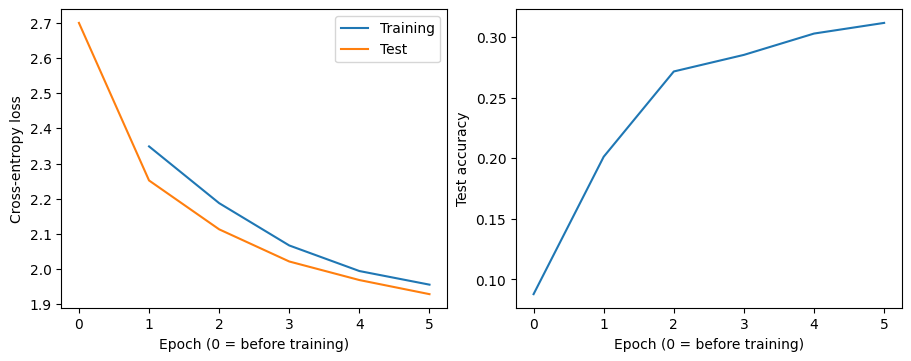

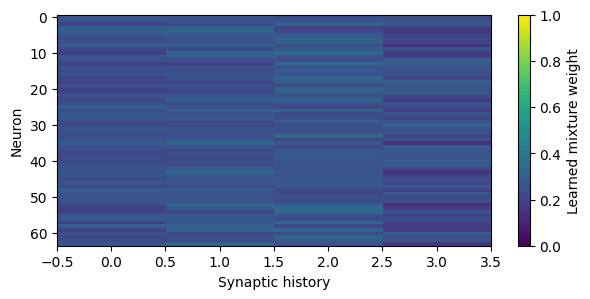

In [12]:
plot_history(history)
plt.show()
mixture = model.net[1].mixture.detach().cpu()
plt.figure(figsize=(7, 3))
plt.imshow(mixture, aspect="auto", vmin=0, vmax=1)
plt.xlabel("Synaptic history")
plt.ylabel("Neuron")
plt.colorbar(label="Learned mixture weight")
plt.show()

The reference five-epoch run improves test accuracy from about 8.8% to 31.2%, with loss falling from 2.700 to 1.929. This gives us a layer that participates in a complete learning task, while keeping the lesson focused on how its states and parameters work.

The heatmap shows how each neuron mixes its synaptic histories after training. Softmax keeps every row normalized, but the rows can adapt independently, so one neuron can favor a different history from another.

For an experiment, train a fresh model with `alpha` fixed but the mixture still learnable. The histories then retain their initial decays while their contributions can change. Comparing the result and heatmap asks a specific question about what each set of custom parameters does.

## 7. Saving and restoring matrix states

We'll first save the trained weights and optimizer in `checkpoints/model.pt`. Then we'll process part of an image sequence and save its memory separately in `checkpoints/states.pt`, along with the input sequence and the cursor that identifies where to continue. Both the synaptic matrix and the membrane vectors take part in the same state snapshot.

In [13]:
checkpoint = checkpoint_dir / "model.pt"
torch.save({"weights": model.state_dict(), "optimizer": optimizer.state_dict(), "width": 64}, checkpoint)
images, labels = next(iter(test_loader))
sequence = images_to_patch_sequence(images[:2].to(device))
model.eval()
model.reset_states()
with torch.no_grad():
    for patch in sequence[:20]:
        model(patch)
    torch.save({"states": model.save_states(), "cursor": 20, "sequence": sequence.cpu()},
               checkpoint_dir / "states.pt")
    expected = torch.stack([model(patch) for patch in sequence[20:]])
    saved_model = torch.load(checkpoint, map_location=device, weights_only=True)
    saved_states = torch.load(checkpoint_dir / "states.pt", map_location=device, weights_only=True)
    restored = CustomPatchSNN(width=saved_model["width"]).to(device).eval()
    restored.load_state_dict(saved_model["weights"])
    restored.load_states(saved_states["states"])
    actual = torch.stack([restored(patch) for patch in saved_states["sequence"][saved_states["cursor"]:]])
print("Restored matrix state:", restored.net[1].syn.shape)
print("Maximum continuation difference:", (actual - expected).abs().max().item())
torch.testing.assert_close(actual, expected)
model.reset_states()

Restored matrix state: torch.Size([2, 64, 4])
Maximum continuation difference: 0.0


The restored matrix has the expected shape, and every remaining output agrees with the uninterrupted run. We construct the same architecture and move it to the target device before loading because hidden states are plain tensor attributes; moving an already-running model doesn't automatically move those tensors.

The reference training and evaluation take roughly four to five seconds on CPU, excluding downloads and figures. The complete program is `python examples/custom_neuron/main.py --device cpu`; it saves the plots, writes separate `model.pt` and `states.pt` files under the example's `checkpoints` folder, and checks the restored continuation.

We've used one matrix for a bank of synaptic histories, but the same declarations can describe other states that your update needs. The important connection is between what each state means, the shape that represents it, and the reset, detach and persistence boundaries of the task.